# 3. A Cox model for default: borrowers versus environment

Notebook 2 showed that, within every credit-score band, 2006 loans defaulted 3 to 5 times more often than 2017 loans. A regression model adjusts for all borrower characteristics at once and asks: **for two loans with the same profile, how much riskier was the 2006 one?**

Because prepayment competes with default, the model is a **cause-specific Cox model**: it describes the hazard of default among loans still running, and prepaid loans are censored at prepayment. (That is correct for the *hazard*; probabilities of default still require the competing-risks machinery of notebook 2.)

In [1]:
import sys
sys.path.insert(0, "../src")
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import concordance_index

from credit_risk.data import load_loans
from credit_risk.survival import cumulative_incidence

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#1a73e8", "#d93025", "#80868b"

loans = load_loans((2006, 2017)).dropna(subset=["fico", "ltv", "dti", "rate"])

# Covariates on interpretable scales. The interest rate is expressed as the premium over the
# median rate of loans originated the same year: rates fell from ~6.4% to ~4.2% between the two
# vintages for reasons unrelated to the borrower, while the premium reflects the lender's view of risk.
X = pd.DataFrame({
    "fico_per_20": (loans["fico"] - 740) / 20,
    "ltv_per_10": (loans["ltv"] - 75) / 10,
    "dti_per_10": (loans["dti"] - 35) / 10,
    "rate_premium": loans["rate"] - loans.groupby("vintage")["rate"].transform("median"),
    "investor": (loans["occupancy"] == "I").astype(int),
    "cash_out_refi": (loans["purpose"] == "C").astype(int),
    "first_time_buyer": (loans["first_time_buyer"] == "Y").astype(int),
    "single_borrower": (loans["n_borrowers"] == 1).astype(int),
    "vintage_2006": (loans["vintage"] == 2006).astype(int),
    "time": loans["time"],
    "default": (loans["event"] == 1).astype(int),
    "vintage": loans["vintage"],
})
len(X)

97062

## The model with a vintage effect

In [2]:
cox = CoxPHFitter()
cox.fit(X.drop(columns="vintage"), duration_col="time", event_col="default")
hr = cox.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
hr.columns = ["hazard ratio", "lower 95%", "upper 95%", "p"]
hr

,hazard ratio,lower 95%,upper 95%,p
covariate,,,,
fico_per_20,0.857,0.851,0.862,0.000e+00
ltv_per_10,1.231,1.211,1.251,1.756e-135
dti_per_10,1.240,1.216,1.264,6.178e-106
rate_premium,1.566,1.485,1.652,4.811e-61
investor,0.677,0.606,0.757,4.914e-12
cash_out_refi,1.428,1.359,1.499,8.201e-46
first_time_buyer,0.934,0.872,1.000,5.080e-02
single_borrower,1.521,1.455,1.591,2.120e-76
vintage_2006,4.575,4.289,4.880,0.000e+00


Reading the hazard ratios:

- **Credit score:** every 20 FICO points *lower* multiplies the default hazard by about 1.17 (= 1 / 0.857).
- **Loan-to-value and debt-to-income:** more leverage, more risk.
- **Rate premium:** loans priced above their year's typical rate carried risk the lender saw and the other variables do not capture.
- **Investor properties:** a hazard ratio *below* 1 looks surprising, but it is conditional on everything else, including the rate premium: lenders charge investors more and demand more equity, so the remaining risk is lower. A coefficient is an effect *given the other variables*, not a stand-alone fact.
- **Vintage 2006:** even after adjusting for everything above, a 2006 loan had several times the default hazard of an identical 2017 loan. That is the environment: the collapse in house prices that left borrowers owing more than their homes were worth.

## Checking the proportional-hazards assumption

The Cox model assumes each hazard ratio is constant over the life of the loan. With 100,000 loans, a formal test will flag tiny departures, so the test statistic matters more than the p-value: which variables violate the assumption *most*?

In [3]:
ph = proportional_hazard_test(cox, X.drop(columns="vintage"), time_transform="rank").summary
ph[["test_statistic", "p"]].sort_values("test_statistic", ascending=False)

,test_statistic,p
fico_per_20,237.053,1.727e-53
single_borrower,29.562,5.416e-08
ltv_per_10,27.002,2.032e-07
cash_out_refi,20.816,5.057e-06
dti_per_10,18.699,1.531e-05
vintage_2006,8.094,4.440e-03
rate_premium,7.483,6.229e-03
investor,0.071,7.893e-01
first_time_buyer,0.013,9.094e-01


The largest violation is the **credit score**: a score measured at origination says less and less about the borrower as the years pass (incomes, debts and house prices change), so its effect fades with loan age. The vintage effect also varies over time, because the crisis struck at a specific *calendar* date. A single hazard ratio averages effects that change over the life of the loan. We estimate both separately by loan age, refitting the model on loans still at risk at the start of each period (left truncation):

In [4]:
def hr_vintage_in_window(start, end):
    w = X[X["time"] > start].copy()
    w["entry"] = start
    w["default"] = ((w["default"] == 1) & (w["time"] <= end)).astype(int)
    w["time"] = w["time"].clip(upper=end)
    m = CoxPHFitter().fit(w.drop(columns="vintage"), duration_col="time", event_col="default", entry_col="entry")
    s = m.summary
    return {"loan age (months)": f"{start + 1}–{end}",
            "HR vintage 2006 vs 2017": s.loc["vintage_2006", "exp(coef)"],
            "95% CI vintage": f"{s.loc['vintage_2006', 'exp(coef) lower 95%']:.2f}–{s.loc['vintage_2006', 'exp(coef) upper 95%']:.2f}",
            "HR per 20 FICO points": s.loc["fico_per_20", "exp(coef)"],
            "defaults in window": int(w["default"].sum())}

windows = pd.DataFrame([hr_vintage_in_window(a, b) for a, b in [(0, 24), (24, 48), (48, 72), (72, 108)]])
windows

,loan age (months),HR vintage 2006 vs 2017,95% CI vintage,HR per 20 FICO points,defaults in window
0,1–24,3.150,2.80–3.54,0.807,2055
1,25–48,6.574,5.84–7.40,0.853,3095
2,49–72,4.376,3.81–5.02,0.902,1785
3,73–108,4.428,3.74–5.24,0.911,894


Two findings hidden inside the single hazard ratios:

- For an otherwise identical loan, being originated in 2006 multiplied the default hazard most in months 25–48 of the loan's life, which for these loans is 2008–2010, the core of the crisis.
- The protective effect of a higher credit score is strongest in the first two years and weakens afterwards (hazard ratio per 20 points moving towards 1).

The proportional-hazards violations are not a nuisance to hide: they *are* findings. An alternative specification stratifies by vintage (a separate baseline hazard per vintage, shared covariate effects); the borrower effects barely change:

In [5]:
strat = CoxPHFitter().fit(X.drop(columns=["vintage_2006"]), duration_col="time", event_col="default", strata=["vintage"])
hr_strat = strat.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]]
hr_strat.columns = ["hazard ratio", "lower 95%", "upper 95%"]
hr_strat

,hazard ratio,lower 95%,upper 95%
covariate,,,
fico_per_20,0.856,0.851,0.862
ltv_per_10,1.231,1.211,1.251
dti_per_10,1.240,1.216,1.264
rate_premium,1.568,1.487,1.654
investor,0.678,0.607,0.757
cash_out_refi,1.427,1.359,1.499
first_time_buyer,0.935,0.873,1.001
single_borrower,1.522,1.456,1.592


## Validation: does a model built on 2006 work on 2017?

A credit model is used on loans it has never seen, in an economy that may be different. The test that matters is **out of time**: fit on 2006, evaluate on 2017. Two separate questions:

1. **Discrimination:** does it still *rank* borrowers correctly? (concordance index; 0.5 = coin flip, 1 = perfect)
2. **Calibration:** does it get the *level* of risk right?

In [6]:
covs = ["fico_per_20", "ltv_per_10", "dti_per_10", "rate_premium", "investor", "cash_out_refi", "first_time_buyer", "single_borrower"]
train, test = X[X["vintage"] == 2006], X[X["vintage"] == 2017]
m06 = CoxPHFitter().fit(train[covs + ["time", "default"]], duration_col="time", event_col="default")
m17 = CoxPHFitter().fit(test[covs + ["time", "default"]], duration_col="time", event_col="default")

def c_index(model, data):
    return concordance_index(data["time"], -model.predict_partial_hazard(data[covs]), data["default"])

pd.DataFrame({
    "concordance on 2006": [c_index(m06, train), c_index(m17, train)],
    "concordance on 2017": [c_index(m06, test), c_index(m17, test)],
}, index=["model fitted on 2006", "model fitted on 2017"])

,concordance on 2006,concordance on 2017
model fitted on 2006,0.738,0.778
model fitted on 2017,0.731,0.790


The ranking transfers almost intact: a model fitted on 2006 sorts 2017 borrowers nearly as well as a model fitted on 2017 itself. Now the level. For each decile of predicted risk in 2017, compare the predicted probability of default within 24 months with what happened (at 24 months prepayment is still small, so the cause-specific and competing-risks probabilities nearly coincide):

In [7]:
horizon = 24
pred06 = 1 - m06.predict_survival_function(test[covs], times=[horizon]).T[horizon]
pred17 = 1 - m17.predict_survival_function(test[covs], times=[horizon]).T[horizon]
decile = pd.qcut(pred17.rank(method="first"), 10, labels=False) + 1
observed = test.assign(decile=decile.values, event=np.where(test["default"] == 1, 1, np.where(loans.loc[test.index, "event"] == 2, 2, 0))) \
               .groupby("decile").apply(lambda g: cumulative_incidence(g["time"], g["event"], horizon)["cif_default"].iloc[-1])
calib = pd.DataFrame({"observed": observed,
                      "predicted, model fitted on 2017": pred17.groupby(decile.values).mean(),
                      "predicted, model fitted on 2006": pred06.groupby(decile.values).mean()})
calib.index.name = "risk decile (2017 loans)"
calib

,observed,"predicted, model fitted on 2017","predicted, model fitted on 2006"
risk decile (2017 loans),,,
1,4.151e-04,8.697e-04,0.008
2,2.076e-04,1.683e-03,0.013
3,1.038e-03,2.480e-03,0.017
4,1.662e-03,3.405e-03,0.020
5,2.492e-03,4.525e-03,0.024
6,3.530e-03,5.967e-03,0.028
7,6.236e-03,7.903e-03,0.033
8,1.226e-02,1.080e-02,0.040
9,1.851e-02,1.603e-02,0.048


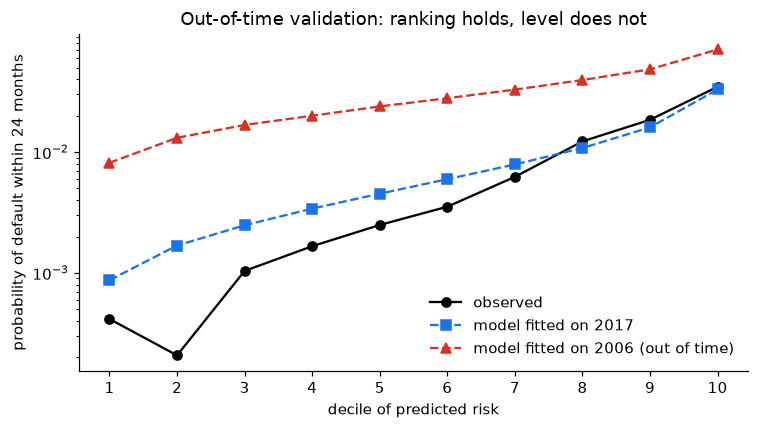

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(calib.index, calib["observed"], "o-", color="black", label="observed")
ax.plot(calib.index, calib["predicted, model fitted on 2017"], "s--", color=BLUE, label="model fitted on 2017")
ax.plot(calib.index, calib["predicted, model fitted on 2006"], "^--", color=RED, label="model fitted on 2006 (out of time)")
ax.set_yscale("log")
ax.set_xlabel("decile of predicted risk")
ax.set_ylabel(f"probability of default within {horizon} months")
ax.set_xticks(range(1, 11))
ax.legend(frameon=False)
ax.set_title("Out-of-time validation: ranking holds, level does not")
fig.tight_layout()
fig.savefig("../figures/out_of_time_calibration.png", bbox_inches="tight")
plt.show()

**The model fitted on the crisis vintage ranks 2017 borrowers correctly but overstates their risk several times over.** This is the central distinction of credit-model validation: *discrimination* (who is riskier) is a property of the borrowers and transfers across time; *calibration* (how risky) depends on the economic cycle and does not. In practice, banks keep the ranking model and recalibrate its level, separating a *through-the-cycle* probability of default from a *point-in-time* one.

In [9]:
hr.to_csv("../results/cox_hazard_ratios.csv")
windows.to_csv("../results/vintage_hr_by_loan_age.csv", index=False)
calib.to_csv("../results/out_of_time_calibration.csv")